In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
stud = pd.read_csv(r"D:\ML Projects\Suprvised practice\Data set\student_performance_classification_dirty.csv")
stud.head(3)
stud.tail(3)

,student_id,age,study_hours,attendance_pct,previous_score,sleep_hours,gender,course,internet_access,passed
609,2383,22.0,3.6,97.6,77.6,8.5,Male,Business,Yes,Yes
610,2366,20.0,2.5,46.1,59.4,5.1,Female,Business,Yes,Yes
611,2511,17.0,1.5,76.2,36.0,4.0,Female,Engineering,No,Yes


In [4]:
stud.info()
print(stud.shape)

<class 'pandas.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   student_id       612 non-null    int64  
 1   age              586 non-null    float64
 2   study_hours      592 non-null    float64
 3   attendance_pct   592 non-null    float64
 4   previous_score   596 non-null    float64
 5   sleep_hours      597 non-null    float64
 6   gender           602 non-null    str    
 7   course           602 non-null    str    
 8   internet_access  601 non-null    str    
 9   passed           612 non-null    str    
dtypes: float64(5), int64(1), str(4)
memory usage: 47.9 KB
(612, 10)


In [5]:
stud.isnull().sum()

student_id          0
age                26
study_hours        20
attendance_pct     20
previous_score     16
sleep_hours        15
gender             10
course             10
internet_access    11
passed              0
dtype: int64

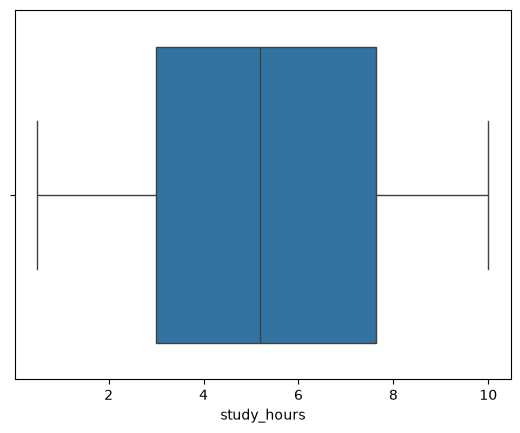

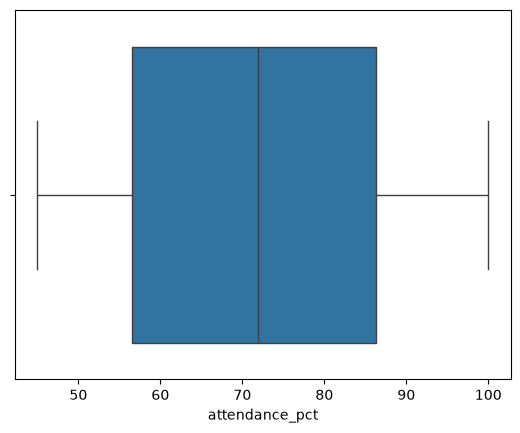

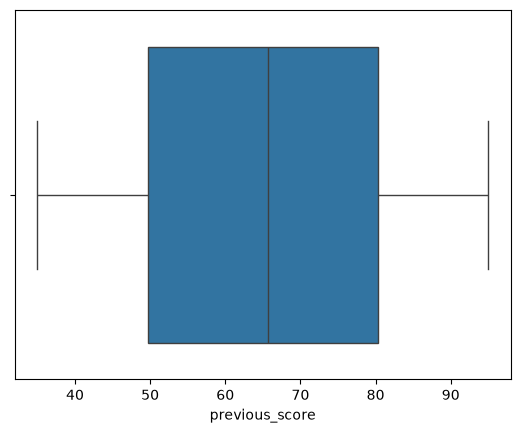

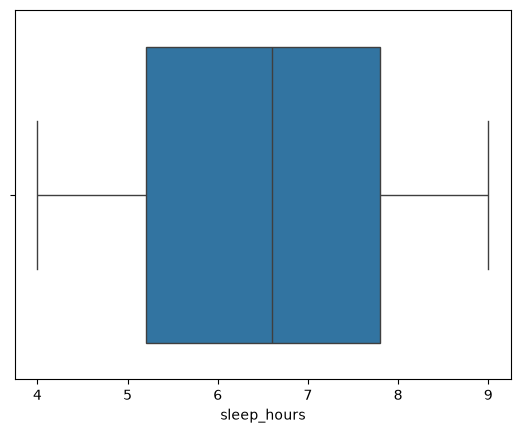

In [6]:
cols = ['study_hours','attendance_pct','previous_score','sleep_hours']

for i in cols:
    sns.boxplot(data=stud,x=i)
    plt.show()

In [7]:
stud['age'].isnull().sum()

np.int64(26)

In [8]:
from sklearn.impute import SimpleImputer
# In above visualisation i can see there is no outliers so i can use mean for replace null value of numeric cols
# for categorical column i'm using mode here to replace nan values

si = SimpleImputer(strategy='mean')

stud[['age','study_hours','attendance_pct','previous_score','sleep_hours']] = si.fit_transform(stud[['age','study_hours',
                                                                                               'attendance_pct',
                                                                                               'previous_score',
                                                                                               'sleep_hours']])

In [9]:
si1 = SimpleImputer(strategy="most_frequent")

stud[['gender','course','internet_access']] = si1.fit_transform(stud[['gender','course','internet_access']])

In [10]:
stud.isnull().sum()

student_id         0
age                0
study_hours        0
attendance_pct     0
previous_score     0
sleep_hours        0
gender             0
course             0
internet_access    0
passed             0
dtype: int64

In [11]:
stud.describe()

,student_id,age,study_hours,attendance_pct,previous_score,sleep_hours
count,612.000000,612.000000,612.000000,612.000000,612.000000,612.000000
mean,2298.614379,22.737201,5.325000,71.692736,65.242282,6.482915
std,173.434390,3.621071,2.675717,16.381371,17.221311,1.446507
min,2001.000000,17.000000,0.500000,45.000000,35.000000,4.000000
25%,2148.750000,20.000000,3.100000,56.950000,50.175000,5.200000
50%,2298.500000,22.737201,5.325000,71.692736,65.242282,6.500000
75%,2448.250000,26.000000,7.600000,85.650000,79.800000,7.700000
max,2600.000000,29.000000,10.000000,100.000000,95.000000,9.000000


In [12]:
stud.drop_duplicates(inplace=True)
stud.duplicated().sum()

np.int64(0)

In [13]:
X = stud.drop(columns=['passed','internet_access'])
y = stud['passed']


In [14]:
from sklearn.preprocessing import LabelEncoder

cols_cat = ['gender','course']
for i in cols_cat:
    le = LabelEncoder()
    X[i] = le.fit_transform(X[i])

print(le.classes_)

for category,i in enumerate(le.classes_):
    print(category, "->", i)

le1 = LabelEncoder()

y = le1.fit_transform(y)


['Arts' 'Business' 'Computer Science' 'Engineering']
0 -> Arts
1 -> Business
2 -> Computer Science
3 -> Engineering


In [15]:
X.info()

<class 'pandas.DataFrame'>
Index: 600 entries, 0 to 611
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   student_id      600 non-null    int64  
 1   age             600 non-null    float64
 2   study_hours     600 non-null    float64
 3   attendance_pct  600 non-null    float64
 4   previous_score  600 non-null    float64
 5   sleep_hours     600 non-null    float64
 6   gender          600 non-null    int64  
 7   course          600 non-null    int64  
dtypes: float64(5), int64(3)
memory usage: 42.2 KB


In [16]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=42,test_size=0.2,stratify=y)

In [21]:
from sklearn.linear_model import LogisticRegression

logi = LogisticRegression()
logi.fit(X_train,y_train)
print(logi.score(X_test,y_test))

#pd.DataFrame(logi.predict([[2366,20.0,2.5,46.1,59.4,5.1,0,2]]))


0.9666666666666667


c:\Users\Hp\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [18]:
# Decision Tree
from sklearn.tree import DecisionTreeClassifier
criterion = ["gini", "entropy", "log_loss"]
#score = []
for x in criterion:
    dt = DecisionTreeClassifier(criterion=x)
    dt.fit(X_train,y_train)
    score = dt.score(X_test,y_test)
    print(f"criterion: {x} score:{score}" )

criterion: gini score:0.9166666666666666
criterion: entropy score:0.9083333333333333
criterion: log_loss score:0.9083333333333333


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier()